# Pallas TPU kernel dataset v4 (release candidate 1): dataset and results companion

This notebook downloads the dataset, checks it, and looks at the oracle results behind it. It runs on a CPU-only machine
(Kaggle CPU or a laptop) from public URLs, with no login.

What the dataset is: supervised fine-tuning data for teaching Gemma 4 E4B to write Pallas TPU kernels from plain-JAX references.
Each training row is a chat: the problem (a reference JAX module) followed by a kernel that a TPU v6e oracle judged, or, for a
labelled minority of 138 rows, that a CPU check verified. Repair rows also carry one or two failed attempts, each followed by its feedback line, before the passing kernel.

Status: **release candidate**. The data freeze is Nov 11, 2026 06:00 UTC, and later repair rounds, the shard D batch and two
pending team decisions can still change the contents. The final release will be tagged `dataset-v4`.

The oracle judges each kernel in 4 steps, and the first failing step is the verdict:
1. It is a real Pallas kernel: a `pallas_call` the output depends on, with only layout, dtype and small integer work outside
   it (otherwise `not_a_kernel`).
2. It compiles and runs (otherwise `compile`, `vmem`, `mosaic`, `timeout` or `runtime`).
3. It matches a float32 answer key on 3 input seeds (otherwise `wrong`).
4. It runs at least 0.7x as fast as XLA (otherwise `correct_slow`).

Links:
- Repository: https://github.com/Art4v/gemma-hackathon-research
- Release: https://github.com/Art4v/gemma-hackathon-research/releases/tag/dataset-v4-rc1
- The datasheet is `README.md` inside the release archive.

Sections: 2 download and verify, 3 load and count, 4 example rows, 5 oracle results, 6 the oracle's step 1 run on CPU.

In [1]:
import hashlib, json, os, pathlib, re, shutil, subprocess, sys, tarfile, urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

REPO = "Art4v/gemma-hackathon-research"
RAW = f"https://raw.githubusercontent.com/{REPO}"
RELEASE_URL = f"https://github.com/{REPO}/releases/download/dataset-v4-rc1/dataset-v4-rc1.tar.gz"

# Everything downloaded goes into a fresh folder, so a rerun never mixes old and new files.
WORK = pathlib.Path("work").resolve()
shutil.rmtree(WORK, ignore_errors=True)
WORK.mkdir()


def fetch(url: str, dest: pathlib.Path) -> pathlib.Path:
    """Download url to dest; an HTTP error (404 and so on) raises."""
    dest.parent.mkdir(parents=True, exist_ok=True)
    with urllib.request.urlopen(url, timeout=120) as r:
        dest.write_bytes(r.read())
    return dest


pd.set_option("display.max_colwidth", 80)
print("working folder:", WORK)

working folder: /private/tmp/claude-501/-Users-karthikvattem-projects-smallpallas/15ea0b31-ef3e-44e9-904b-025d131c69f0/scratchpad/notebook/work


## 2. Download and verify the release

The archive holds `SHA256SUMS`, a checksum for every other file in the bundle. The cell below checks each one and stops with an
error if any file is missing, unlisted or different.

In [2]:
tarball = fetch(RELEASE_URL, WORK / "dataset-v4-rc1.tar.gz")
print(f"{tarball.name}: {tarball.stat().st_size:,} bytes, sha256 {hashlib.sha256(tarball.read_bytes()).hexdigest()}")

with tarfile.open(tarball) as tf:
    # filter="data" refuses absolute paths, links out of the folder and device files (Python 3.12+, backported to 3.8.17+)
    tf.extractall(WORK, **({"filter": "data"} if hasattr(tarfile, "data_filter") else {}))
DATA = WORK / "dataset-v4-rc1"

listed = {}
for line in (DATA / "SHA256SUMS").read_text().splitlines():
    digest, name = line.split(maxsplit=1)  # "<sha256>  ./path"
    listed[name.lstrip("*").removeprefix("./")] = digest
on_disk = {p.relative_to(DATA).as_posix() for p in DATA.rglob("*") if p.is_file()} - {"SHA256SUMS"}

checks = pd.DataFrame(
    [{"file": f, "bytes": (DATA / f).stat().st_size if (DATA / f).is_file() else None,
      "expected": listed.get(f), "actual": hashlib.sha256((DATA / f).read_bytes()).hexdigest() if (DATA / f).is_file() else None}
     for f in sorted(set(listed) | on_disk)])
checks["status"] = np.select([checks.expected.isna(), checks.actual.isna(), checks.expected == checks.actual],
                             ["not in SHA256SUMS", "missing", "ok"], "MISMATCH")
display(checks[["file", "bytes", "status", "actual"]])
bad = checks[checks.status != "ok"]
if len(bad):
    raise RuntimeError(f"SHA256SUMS check failed for {len(bad)} file(s):\n{bad[['file', 'status']].to_string(index=False)}")
print(f"all {len(checks)} files match SHA256SUMS")

dataset-v4-rc1.tar.gz: 1,857,234 bytes, sha256 65e39529c2548d556433dafd4c03adb4578e2b35e82942e6d142b7a027d5a755


,file,bytes,status,actual
0,ATTRIBUTION.csv,196797,ok,870e53445483b7498391d7b9284e52001d4e5a8571de7ce6d73e6bb80596b32a
1,LICENSES/KernelBench-MIT.txt,1143,ok,fb5917dd8e4476fa75e89ef6f03dccf07d4859636bc23c7db50e6c0413887b9e
2,LICENSES/KernelBook-June9-Researcher-Reciprocity-License.txt,12135,ok,840471894333d8ec3771dc588e9b6d048c2181448e4d7b02cab516f24a4118d1
3,LICENSES/KernelBook-NOTICE.md,803,ok,f1331c06e04e1694926a5f75fe4248c0d4c244ed4b442c811f9b0e4382eba5a3
4,MANIFEST.json,1293,ok,1121dcb8cfc8530e438fd300ca954b8ae1d74d19273358a8d290e830e2aef18c
5,README.md,6003,ok,10d24102f1a6640a57caafe75738b52a10f34079f16768ef33da7fe9d136cca7
6,coverage.txt,1006,ok,f344183ab82f06f70f7c66fc26069fc2dcdd7bbf432be78d0305f3131d943340
7,train.jsonl,20035600,ok,0ca3f472f565591dda07d0ba19ca41c839d8d40b5780a2004e3c49756d7793d5
8,val.jsonl,167670,ok,8abc71aecc450f18f5d4cc68409ebc2d8afceb3a25debea2e74cf7a1b9bd078f
9,verification.jsonl,877648,ok,2abcb999a262308f4d42009a6ac366d6a2be7c5484621326a464813760ecc2d6


all 10 files match SHA256SUMS


## 3. Load the splits and check the counts

`verification.jsonl` has one record per training row (same `example_id`): how its target was verified, the final oracle verdict,
and the oracle job ids. The asserts below compare against the counts in the datasheet.

In [3]:
train = pd.read_json(DATA / "train.jsonl", lines=True)
val = pd.read_json(DATA / "val.jsonl", lines=True)
ver = pd.read_json(DATA / "verification.jsonl", lines=True)
manifest = json.loads((DATA / "MANIFEST.json").read_text())

assert train.example_id.is_unique and set(train.example_id) == set(ver.example_id), "verification.jsonl must cover train 1:1"
n_train = len(train)
train = train.merge(ver, on=["example_id", "kind"], validate="one_to_one")
assert len(train) == n_train, "kind differs between train.jsonl and verification.jsonl"
print(f"train {len(train):,} rows, {train.task.nunique():,} distinct tasks; val {len(val)} rows, {val.task.nunique()} tasks")
print("train columns:", list(train.columns))

train 2,717 rows, 1,398 distinct tasks; val 26 rows, 23 tasks
train columns: ['example_id', 'kind', 'messages', 'source', 'task', 'teacher', 'thinking', 'final_verdict', 'oracle_job_ids', 'verification', 'broken_verdict', 'feedback', 'mutation', 'target_static_verdict', 'lowered', 'nearest_exam', 'numerics', 'ref_precision', 'oracle_shas', 'part', 'speed_vs_xla']


In [4]:
by_kind = pd.crosstab(train.kind, train.verification, margins=True, margins_name="total")
by_source = train.source.value_counts().rename_axis("source").to_frame("rows")
by_verification = (train.groupby(["verification", "final_verdict"]).size().rename("rows").reset_index())
print("Rows by kind and how the target was verified"); display(by_kind)
print("Rows by source"); display(by_source)
print("Rows by verification"); display(by_verification)

Rows by kind and how the target was verified


verification,cpu,tpu,tpu_correct_slow,total
kind,,,,
correct_slow,0,0,54,54
generated,55,0,0,55
repair,0,110,0,110
repair_injected,0,1167,0,1167
shape_variant,83,0,0,83
single,0,1248,0,1248
total,138,2525,54,2717


Rows by source


,rows
source,
kernelbook,1014
kernelbench,817
authored,806
generated,55
github,15
scraped,10


Rows by verification


,verification,final_verdict,rows
0,cpu,cpu_verified,138
1,tpu,pass,2525
2,tpu_correct_slow,correct_slow,54


In [5]:
# The datasheet's numbers (README.md, "Counts (training set)").
EXPECTED_KIND = {"single": 1248, "repair": 110, "repair_injected": 1167, "shape_variant": 83, "generated": 55, "correct_slow": 54}
EXPECTED_SOURCE = {"kernelbook": 1014, "kernelbench": 817, "authored": 806, "generated": 55, "github": 15, "scraped": 10}
EXPECTED_VERIFICATION = {("tpu", "pass"): 2525, ("tpu_correct_slow", "correct_slow"): 54, ("cpu", "cpu_verified"): 138}

assert len(train) == 2717 == manifest["n_train"], len(train)
assert len(val) == 26 == manifest["n_val"], len(val)
assert train.task.nunique() == 1398, train.task.nunique()
assert train.kind.value_counts().to_dict() == EXPECTED_KIND
assert train.source.value_counts().to_dict() == EXPECTED_SOURCE
assert train.groupby(["verification", "final_verdict"]).size().to_dict() == EXPECTED_VERIFICATION
assert not set(train.task) & set(val.task), "a validation task also appears in train"
print("all datasheet counts reproduced: 2,717 train / 26 val / 1,398 tasks; 2,525 TPU pass, 54 TPU correct_slow, 138 CPU only")

all datasheet counts reproduced: 2,717 train / 26 val / 1,398 tasks; 2,525 TPU pass, 54 TPU correct_slow, 138 CPU only


## 4. One single-turn row and one repair row

Messages are printed as they are stored; code longer than 25 lines is cut, with the number of hidden lines shown.

In [6]:
MAX_LINES = 25


def show_row(row) -> None:
    print(f"example_id {row.example_id}\nkind {row.kind}, source {row.source}, teacher {row.teacher}, "
          f"verified by {row.verification} ({row.final_verdict}), oracle jobs {row.oracle_job_ids}")
    for i, m in enumerate(row.messages):
        lines = m["content"].splitlines()
        cut = lines[:MAX_LINES] + ([f"... ({len(lines) - MAX_LINES} more lines)"] if len(lines) > MAX_LINES else [])
        print(f"\n----- message {i}: {m['role']} ({len(m['content']):,} chars) -----")
        print("\n".join(cut))


single_row = train[train.kind == "single"].iloc[0]
repair_row = train[train.kind == "repair"].iloc[0]
show_row(single_row)

example_id authored__attention_alibi__alibi_causal_mha.single.a1
kind single, source authored, teacher claude, verified by tpu (pass), oracle jobs ['dataset-pilot-r1']

----- message 0: system (550 chars) -----
You are a code model that writes TPU kernels in JAX Pallas. Given a reference JAX function, reply with one Python code block only. Define workload(*inputs) with the same signature and outputs as the reference, reading shapes from inputs at runtime. Run the main computation inside pl.pallas_call, using the imports from jax.experimental import pallas as pl and from jax.experimental.pallas import tpu as pltpu. The kernel runs on a TPU v6e at the reference's full size. Use the largest blocks fitting in memory to be as fast as the jax.jit reference.

----- message 1: user (2,154 chars) -----
Here is the reference JAX function:
```python
"""Causal multi-head attention with ALiBi per-head linear positional bias (BLOOM / MPT style)."""
import jax
import jax.numpy as jnp

CONFIG = {
    

In [7]:
show_row(repair_row)

example_id authored__attention_decode_mqa__mqa_decode_padded_cache.repair.a2
kind repair, source authored, teacher claude, verified by tpu (pass), oracle jobs ['dataset-b1-r1', 'dataset-b1-r2']

----- message 0: system (550 chars) -----
You are a code model that writes TPU kernels in JAX Pallas. Given a reference JAX function, reply with one Python code block only. Define workload(*inputs) with the same signature and outputs as the reference, reading shapes from inputs at runtime. Run the main computation inside pl.pallas_call, using the imports from jax.experimental import pallas as pl and from jax.experimental.pallas import tpu as pltpu. The kernel runs on a TPU v6e at the reference's full size. Use the largest blocks fitting in memory to be as fast as the jax.jit reference.

----- message 1: user (1,737 chars) -----
Here is the reference JAX function:
```python
"""Multi-query attention single-token decode: q·K^T (one shared KV head) -> length mask -> softmax -> ·V over a padded cach

## 5. Oracle results

These are the oracle's verdict files for the parts built after the v3 base (`MANIFEST.json`, `part_commits`), read at fixed commits
so the numbers do not move. They hold every candidate the oracle judged, including the ones that failed and did not become
training rows. KernelBook (`kbk`) ran three rounds: round 2 candidates are new attempts on tasks that failed round 1, and round 3 on
tasks that failed round 2 (the last column of the round table checks this).

In [8]:
VERDICT_FILES = {
    "6dee7126d0926fad28555b7e7db7f5d1584d1401": ["dataset-kbk-r1", "dataset-kbk-r2", "dataset-kbk-r3", "dataset-prod-r1"],
    "f3bde09850cea9c01a2abe68b553139b00620747": ["dataset-kbkc-r1"],
    "20e30a655f0ffe5c505de4f7c244ffb271b521c9": ["dataset-m1-r1", "dataset-m1-r2", "dataset-m1-r3"],
}
REQUIRED_KEYS = {"accepted", "candidate_id", "feedback", "job_id", "oracle_sha", "speed_vs_xla", "verdict", "row"}

records = []
for commit, names in VERDICT_FILES.items():
    for name in names:
        url = f"{RAW}/{commit}/dataset/verdicts/{name}.jsonl"
        lines = fetch(url, WORK / "verdicts" / f"{name}.jsonl").read_text().splitlines()
        recs = [json.loads(l) for l in lines if l.strip()]
        missing = [r.get("candidate_id") for r in recs if not REQUIRED_KEYS <= r.keys()]
        assert not missing, f"{name}: records without the expected keys: {missing[:5]}"
        assert {r["job_id"] for r in recs} == {name}, f"{name}: unexpected job_id values"
        records += [{**r, "commit": commit[:7]} for r in recs]
        print(f"{len(recs):5d} verdicts  {url}")

verdicts = pd.DataFrame(records)
verdicts["task"] = verdicts.row.map(lambda r: r["task"])
verdicts["correct"] = verdicts.row.map(lambda r: r.get("correct") is True)
print(f"{len(verdicts):,} verdict records in {verdicts.job_id.nunique()} jobs")

  777 verdicts  https://raw.githubusercontent.com/Art4v/gemma-hackathon-research/6dee7126d0926fad28555b7e7db7f5d1584d1401/dataset/verdicts/dataset-kbk-r1.jsonl

  114 verdicts  https://raw.githubusercontent.com/Art4v/gemma-hackathon-research/6dee7126d0926fad28555b7e7db7f5d1584d1401/dataset/verdicts/dataset-kbk-r2.jsonl


   58 verdicts  https://raw.githubusercontent.com/Art4v/gemma-hackathon-research/6dee7126d0926fad28555b7e7db7f5d1584d1401/dataset/verdicts/dataset-kbk-r3.jsonl
   22 verdicts  https://raw.githubusercontent.com/Art4v/gemma-hackathon-research/6dee7126d0926fad28555b7e7db7f5d1584d1401/dataset/verdicts/dataset-prod-r1.jsonl


  314 verdicts  https://raw.githubusercontent.com/Art4v/gemma-hackathon-research/f3bde09850cea9c01a2abe68b553139b00620747/dataset/verdicts/dataset-kbkc-r1.jsonl


   94 verdicts  https://raw.githubusercontent.com/Art4v/gemma-hackathon-research/20e30a655f0ffe5c505de4f7c244ffb271b521c9/dataset/verdicts/dataset-m1-r1.jsonl


   13 verdicts  https://raw.githubusercontent.com/Art4v/gemma-hackathon-research/20e30a655f0ffe5c505de4f7c244ffb271b521c9/dataset/verdicts/dataset-m1-r2.jsonl


    6 verdicts  https://raw.githubusercontent.com/Art4v/gemma-hackathon-research/20e30a655f0ffe5c505de4f7c244ffb271b521c9/dataset/verdicts/dataset-m1-r3.jsonl
1,398 verdict records in 8 jobs


In [9]:
counts = pd.crosstab(verdicts.job_id, verdicts.verdict, margins=True, margins_name="total")
lead = [c for c in ("pass", "correct_slow") if c in counts.columns]
counts = counts[lead + sorted(c for c in counts.columns if c not in lead + ["total"]) + ["total"]]
print("Verdict counts per oracle job"); display(counts)

Verdict counts per oracle job


verdict,pass,correct_slow,compile,harness_oom,mosaic,not_a_kernel,runtime,wrong,total
job_id,,,,,,,,,
dataset-kbk-r1,595,143,1,3,22,7,1,5,777
dataset-kbk-r2,53,58,1,0,1,1,0,0,114
dataset-kbk-r3,27,24,0,4,2,0,1,0,58
dataset-kbkc-r1,256,50,1,1,3,2,0,1,314
dataset-m1-r1,81,10,0,0,1,0,0,2,94
dataset-m1-r2,5,8,0,0,0,0,0,0,13
dataset-m1-r3,0,6,0,0,0,0,0,0,6
dataset-prod-r1,21,0,0,1,0,0,0,0,22
total,1038,299,3,9,29,10,2,8,1398


In [10]:
kbk = verdicts[verdicts.job_id.str.fullmatch(r"dataset-kbk-r\d")]
rounds, passed_so_far, r1_tasks, prev_failed = [], set(), None, None
for job, g in kbk.groupby("job_id", sort=True):
    passed = set(g.task[g.verdict == "pass"])
    passed_so_far |= passed
    r1_tasks = r1_tasks or set(g.task)
    retries_only = None if prev_failed is None else set(g.task) <= prev_failed
    prev_failed = set(g.task) - passed
    rounds.append({"round": job.rsplit("-", 1)[1], "candidates": len(g), "pass": len(passed), "pass rate": len(passed) / len(g),
                   "tasks passed so far": len(passed_so_far), "share of round-1 tasks": len(passed_so_far) / len(r1_tasks),
                   "only retries of the previous round's failures": retries_only})
kbk_rounds = pd.DataFrame(rounds).set_index("round")
print("KernelBook pass rate by repair round")
pct = lambda col: kbk_rounds[col].map("{:.1%}".format)
display(kbk_rounds.assign(**{"pass rate": pct("pass rate"), "share of round-1 tasks": pct("share of round-1 tasks")}))

KernelBook pass rate by repair round


,candidates,pass,pass rate,tasks passed so far,share of round-1 tasks,only retries of the previous round's failures
round,,,,,,
r1,777,595,76.6%,595,76.6%,None
r2,114,53,46.5%,648,83.4%,True
r3,58,27,46.6%,675,86.9%,True


The histogram shows `speed_vs_xla = t_xla / t_kernel` for every kernel the oracle found correct on all 3 seeds, across all 8 jobs.
Kernels left of the dashed line are `correct_slow`; the rest `pass`. The datasheet notes that a kernel within about 10% of the
bar can change verdict between two runs.

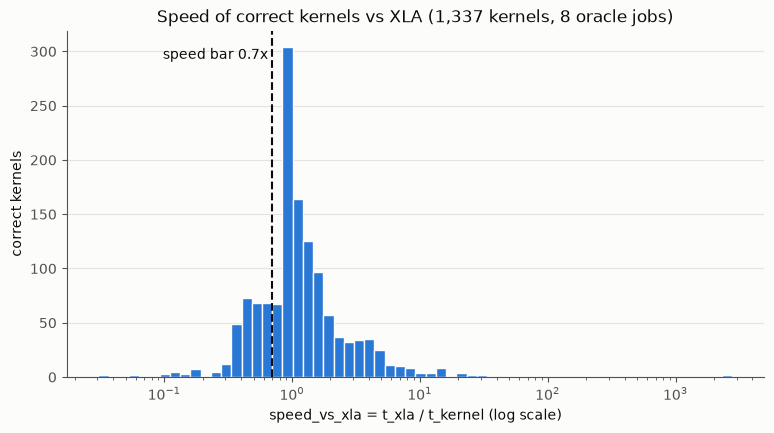

correct kernels: 1,337; below 0.7x: 299; at or above: 1,038; median 1.01x; range 0.033x to 2,770x


In [11]:
SPEED_BAR = 0.7
# One series on an opaque light surface with dark ink, so the image reads the same in light and dark notebook themes.
INK, MUTED, SURFACE, SERIES = "#0b0b0b", "#52514e", "#fcfcfb", "#2a78d6"

speeds = verdicts.loc[verdicts.correct & verdicts.speed_vs_xla.notna(), "speed_vs_xla"].astype(float)
# bins 0.08 decades wide with an edge at the bar, so no bin mixes pass and correct_slow kernels
lo, hi = np.log10(speeds.min() / SPEED_BAR), np.log10(speeds.max() / SPEED_BAR)
bins = SPEED_BAR * 10 ** (0.08 * np.arange(np.floor(lo / 0.08), np.ceil(hi / 0.08) + 1))
with plt.rc_context({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
                     "text.color": INK, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
                     "axes.edgecolor": MUTED}):
    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.hist(speeds, bins=bins, color=SERIES, edgecolor=SURFACE, linewidth=1)
    ax.set_xscale("log")
    ax.axvline(SPEED_BAR, color=INK, linestyle="--", linewidth=1.5)
    ax.text(SPEED_BAR / 1.08, ax.get_ylim()[1] * 0.95, f"speed bar {SPEED_BAR}x", ha="right", va="top", color=INK)
    ax.set_xlabel("speed_vs_xla = t_xla / t_kernel (log scale)")
    ax.set_ylabel("correct kernels")
    ax.set_title(f"Speed of correct kernels vs XLA ({len(speeds):,} kernels, 8 oracle jobs)")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e4e3df", linewidth=0.8)
    ax.set_axisbelow(True)
    plt.show()

below = int((speeds < SPEED_BAR).sum())
print(f"correct kernels: {len(speeds):,}; below {SPEED_BAR}x: {below:,}; at or above: {len(speeds) - below:,}; "
      f"median {speeds.median():.2f}x; range {speeds.min():.3f}x to {speeds.max():,.0f}x")

In [12]:
shas = sorted(set(verdicts.oracle_sha) | set(verdicts.row.map(lambda r: r.get("oracle_sha"))))
print("distinct oracle_sha values (record and row level):", shas)
assert shas == ["c9a07d9298a1"], shas

distinct oracle_sha values (record and row level): ['c9a07d9298a1']


## 6. Run the oracle's step 1 on CPU

Step 1 (is it a real Pallas kernel) needs no TPU: the oracle traces the solution to a jaxpr at the task's full input shapes, runs
nothing, and checks that a `pallas_call` is present, that the output depends on one, and that nothing heavy happens outside it.
This section downloads the oracle from `main` at a fixed commit, packs the single-turn row from section 4 into an oracle job, and
runs it with `--static-only --cpu-smoke`. Then it does the same for a disguised copy that computes the answer with plain `jnp`
and calls a trivial `pallas_call` whose result is thrown away.

The oracle pins JAX 0.10.2. The next cell installs that version only if JAX is missing or a different version.

In [13]:
import importlib.metadata

JAX_PIN = "0.10.2"
try:
    have = importlib.metadata.version("jax")
except importlib.metadata.PackageNotFoundError:
    have = None
if have != JAX_PIN:
    print(f"jax {have} found; installing jax=={JAX_PIN}")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", f"jax=={JAX_PIN}"])
print("jax", importlib.metadata.version("jax"))

jax 0.10.2


In [14]:
ORACLE_COMMIT = "813b2be155a7acab09ba6f451e275c5ea316eed3"
ORACLE = WORK / "oracle"
for name in ("tpu_oracle.py", "outside_ops.py", "tpu_check.py", "make_pack.py"):
    fetch(f"{RAW}/{ORACLE_COMMIT}/oracle/{name}", ORACLE / name)

# oracle_sha is the first 12 hex digits of sha256(tpu_oracle.py + tpu_check.py + outside_ops.py), as tpu_oracle._provenance computes it
local_sha = hashlib.sha256(b"".join((ORACLE / n).read_bytes() for n in ("tpu_oracle.py", "tpu_check.py", "outside_ops.py"))).hexdigest()[:12]
print("oracle files at", ORACLE_COMMIT[:7], "hash to", local_sha)
assert local_sha == "c9a07d9298a1", "this oracle is not the code that judged the dataset"

oracle files at 813b2be hash to c9a07d9298a1


In [15]:
FENCE = re.compile(r"```python\n(.*?)```", re.S)


def only_block(text: str) -> str:
    blocks = FENCE.findall(text)
    assert len(blocks) == 1, f"expected one python block, found {len(blocks)}"
    return blocks[0]


msgs = single_row.messages
assert [m["role"] for m in msgs] == ["system", "user", "assistant"]
ref_code = only_block(msgs[1]["content"])     # the reference module: CONFIG, create_inputs, workload
kernel_code = only_block(msgs[2]["content"])  # the target kernel

# The disguise: the reference's own jnp workload renamed, plus a pallas_call that copies a zeros tile and is never used.
disguised_code, n = re.subn(r"^def workload\(", "def _reference_workload(", ref_code, count=1, flags=re.M)
assert n == 1
disguised_code += """

from jax.experimental import pallas as pl


def _copy_kernel(x_ref, o_ref):
    o_ref[...] = x_ref[...]


def workload(*args):
    unused = pl.pallas_call(_copy_kernel, out_shape=jax.ShapeDtypeStruct((8, 128), jnp.float32))(jnp.zeros((8, 128), jnp.float32))
    return _reference_workload(*args)
"""
print(f"task {single_row.task}: reference {len(ref_code):,} chars, kernel {len(kernel_code):,} chars, "
      f"disguised {len(disguised_code):,} chars")

task authored__attention_alibi__alibi_causal_mha: reference 2,050 chars, kernel 3,229 chars, disguised 2,359 chars


In [16]:
def static_check(item_id: str, code: str) -> dict:
    """Build a 1-item oracle job with make_pack.py, run tpu_oracle.py --static-only --cpu-smoke on it, return the result row."""
    job = WORK / "jobs" / item_id
    items = WORK / "jobs" / f"{item_id}.items.jsonl"
    items.parent.mkdir(parents=True, exist_ok=True)
    items.write_text(json.dumps({"id": item_id, "task": single_row.task, "ref_code": ref_code, "code": code,
                                 "model": single_row.teacher}) + "\n")
    # The downloaded oracle has no git checkout to read its commit from; run.sh passes it the same way, through ORACLE_COMMIT.
    run = lambda *cmd: subprocess.run([sys.executable, *map(str, cmd)], capture_output=True, text=True,
                                      env={**os.environ, "ORACLE_COMMIT": ORACLE_COMMIT[:7]})
    p = run(ORACLE / "make_pack.py", items, job, "--job-id", f"companion-{item_id}", "--owner", "notebook", "--step", "static")
    if p.returncode:
        raise RuntimeError(f"make_pack.py failed:\n{p.stderr}")
    print(p.stdout.strip())
    out = job / "static.jsonl"
    p = run(job / "tpu_oracle.py", job / "pack.json", out, "--static-only", "--cpu-smoke")
    if p.returncode:
        raise RuntimeError(f"tpu_oracle.py failed:\n{p.stderr[-3000:]}")
    print(p.stdout.strip())
    rows = [r for r in map(json.loads, filter(str.strip, out.read_text().splitlines())) if not r.get("meta")]
    assert len(rows) == 1, rows
    return rows[0]


results = [static_check("real", kernel_code), static_check("disguised", disguised_code)]

/private/tmp/claude-501/-Users-karthikvattem-projects-smallpallas/15ea0b31-ef3e-44e9-904b-025d131c69f0/scratchpad/notebook/work/jobs/real: 1 items, 1 shards, oracle unknown sha c9a07d9298a1


{"meta": true, "oracle": true, "jax": "0.10.2", "platform": "cpu", "device_kind": "cpu", "n_devices": 1, "shard": "0/1", "items": 1, "seeds": [0, 1, 2], "speed_bar": 0.7, "timeout_s": 480, "oracle_commit": "813b2be", "oracle_sha": "c9a07d9298a1", "static_only": true, "cpu_smoke": true}
0 real static_ok None
/private/tmp/claude-501/-Users-karthikvattem-projects-smallpallas/15ea0b31-ef3e-44e9-904b-025d131c69f0/scratchpad/notebook/work/jobs/disguised: 1 items, 1 shards, oracle unknown sha c9a07d9298a1


{"meta": true, "oracle": true, "jax": "0.10.2", "platform": "cpu", "device_kind": "cpu", "n_devices": 1, "shard": "0/1", "items": 1, "seeds": [0, 1, 2], "speed_bar": 0.7, "timeout_s": 480, "oracle_commit": "813b2be", "oracle_sha": "c9a07d9298a1", "static_only": true, "cpu_smoke": true}
0 disguised not_a_kernel None not a Pallas kernel: heavy work outside pallas_call: add, div, dot_general, exp, le, mul, reduce_max, reduce_sum, select


In [17]:
COLS = ["id", "verdict", "is_kernel", "pallas_calls", "output_depends_on_pallas", "outside", "outside_disallowed",
        "outside_metadata_ok", "oracle_sha", "jax", "device_kind"]
static = pd.DataFrame(results)[COLS].set_index("id")
display(static.T)
for r in results:
    print(f"{r['id']}: {r['verdict']}. {r['feedback']}")

real, fake = results
assert real["verdict"] == "static_ok" and real["is_kernel"] and real["output_depends_on_pallas"], real
assert fake["verdict"] == "not_a_kernel" and not fake["is_kernel"] and not fake["output_depends_on_pallas"], fake
assert {real["oracle_sha"], fake["oracle_sha"]} == {"c9a07d9298a1"}
print(f"\nOn the TPU this row's kernel was judged {single_row.final_verdict!r} (jobs {single_row.oracle_job_ids}).")

id,real,disguised
verdict,static_ok,not_a_kernel
is_kernel,True,False
pallas_calls,1,1
output_depends_on_pallas,True,False
outside,{},"{'broadcast_in_dim': 11, 'dot_general': 2, 'mul': 2, 'iota': 2, 'sub': 2, 'c..."
outside_disallowed,[],"[add, div, dot_general, exp, le, mul, reduce_max, reduce_sum, select_n, sub]"
outside_metadata_ok,[],[]
oracle_sha,c9a07d9298a1,c9a07d9298a1
jax,0.10.2,0.10.2
device_kind,cpu,cpu


real: static_ok. 
disguised: not_a_kernel. not a Pallas kernel: heavy work outside pallas_call: add, div, dot_general, exp, le, mul, reduce_max, reduce_sum, select_n, sub. Do the computation inside pl.pallas_call; outside it use only layout and dtype ops (reshape, transpose, pad, astype).

On the TPU this row's kernel was judged 'pass' (jobs ['dataset-pilot-r1']).


The real kernel passes step 1 (`static_ok`). The disguised copy also contains a `pallas_call`, but the oracle rejects it as
`not_a_kernel`: the contractions, exponentials and reductions run outside the kernel on float data, and the output does not depend
on the `pallas_call` at all. Steps 2 to 4 need the TPU: under `--cpu-smoke` without `--static-only` the oracle would run Pallas in
interpret mode on CPU, which tests the plumbing but gives timings that mean nothing.